# NFL Fourth-Down Trends and Bears vs. Packers Prediction

## Project Overview

This notebook contains two analyses:

1. **Historical Fourth-Down Trends (2000–2025):** Examine how frequently NFL teams attempt fourth-down conversions, how successful those attempts are, and how their expected points added (EPA) compares with punting.

2. **Bears vs. Packers Prediction (2026):** Analyze team performance and develop a predictive model for the Christmas Day 2026 matchup.

All 2026 data used for the prediction will be restricted to games played on or before November 17, 2026.

## 1. Setup and Imports

In [1]:
import polars as pl
import pandas as pd
import numpy as np

import nflreadpy as nfl

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    confusion_matrix
)

pd.set_option("display.max_columns", None)

## 2. Data Acquisition

We use NFL play-by-play data from nflverse, accessed through the `nflreadpy` Python package.

- Historical dataset: 2000–2025 NFL regular seasons.
- Current-season dataset: 2026 NFL regular season, restricted to games played on or before November 17, 2026.

The historical dataset will be used to investigate long-term fourth-down trends and train predictive models. The 2026 dataset will be used to evaluate the Bears and Packers without incorporating information from after the prediction cutoff.

In [2]:
# Load historical NFL play-by-play data (2000–2025)

historical_seasons = list(range(2000, 2026))

historical_pbp = nfl.load_pbp(historical_seasons)

# Keep regular-season games only
historical_pbp = historical_pbp.filter(
    pl.col("season_type") == "REG"
)

# Verify the dataset
print("Historical seasons:",
      historical_pbp["season"].min(),
      "through",
      historical_pbp["season"].max())

print("Total historical plays:", historical_pbp.height)

print("Number of seasons:",
      historical_pbp["season"].n_unique())

Historical seasons: 2000 through 2025
Total historical plays: 1181016
Number of seasons: 26


In [3]:
# Load 2026 NFL play-by-play data

pbp_2026 = nfl.load_pbp(2026)

# Restrict to regular-season games through November 17, 2026
cutoff_date = "2026-11-17"

pbp_2026 = pbp_2026.filter(
    (pl.col("season_type") == "REG")
    & (pl.col("game_date") <= cutoff_date)
)

# Verify the date range
print(
    pbp_2026.select(
        pl.col("game_date").min().alias("first_game"),
        pl.col("game_date").max().alias("last_game")
    )
)

print("Total 2026 plays:", pbp_2026.height)

shape: (1, 2)
┌────────────┬────────────┐
│ first_game ┆ last_game  │
│ ---        ┆ ---        │
│ str        ┆ str        │
╞════════════╪════════════╡
│ 2026-09-09 ┆ 2026-11-16 │
└────────────┴────────────┘
Total 2026 plays: 26246


In [4]:
print("Historical seasons:")
print(
    historical_pbp
    .select("season")
    .unique()
    .sort("season")
    .to_series()
    .to_list()
)

print("\n2026 seasons:")
print(
    pbp_2026
    .select("season")
    .unique()
    .sort("season")
    .to_series()
    .to_list()
)

Historical seasons:
[2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

2026 seasons:
[2026]


## 3. Historical Fourth-Down Analysis (2000–2025)

This section examines how NFL teams' fourth-down decision-making has evolved over 26 regular seasons.

We investigate three questions:

1. How has the frequency of going for it on fourth down changed over time?
2. How have fourth-down conversion rates changed?
3. How has the average expected points added (EPA) of going for it compared with punting changed?

We first examine fourth-down play classifications to establish consistent definitions for the analysis.

In [5]:
# Select all fourth-down plays from 2000–2025
fourth_down = historical_pbp.filter(
    pl.col("down") == 4
)

# Count the different types of fourth-down plays
play_type_counts = (
    fourth_down
    .group_by("play_type")
    .len()
    .sort("len", descending=True)
)

print(play_type_counts)

shape: (8, 2)
┌────────────┬───────┐
│ play_type  ┆ len   │
│ ---        ┆ ---   │
│ str        ┆ u32   │
╞════════════╪═══════╡
│ punt       ┆ 60478 │
│ field_goal ┆ 23531 │
│ pass       ┆ 8871  │
│ no_play    ┆ 5837  │
│ run        ┆ 5435  │
│ qb_kneel   ┆ 77    │
│ null       ┆ 30    │
│            ┆ 22    │
└────────────┴───────┘


In [6]:
# Examine fourth-down play classifications by season
fourth_down_by_season = (
    fourth_down
    .group_by(["season", "play_type"])
    .len()
    .pivot(
        on="play_type",
        index="season",
        values="len"
    )
    .sort("season")
    .fill_null(0)
)

print(fourth_down_by_season)

shape: (26, 9)
┌────────┬──────────┬─────┬─────────┬───┬──────┬────────────┬─────┬──────┐
│ season ┆ qb_kneel ┆     ┆ no_play ┆ … ┆ punt ┆ field_goal ┆ run ┆ null │
│ ---    ┆ ---      ┆ --- ┆ ---     ┆   ┆ ---  ┆ ---        ┆ --- ┆ ---  │
│ i32    ┆ u32      ┆ u32 ┆ u32     ┆   ┆ u32  ┆ u32        ┆ u32 ┆ u32  │
╞════════╪══════════╪═════╪═════════╪═══╪══════╪════════════╪═════╪══════╡
│ 2000   ┆ 0        ┆ 0   ┆ 198     ┆ … ┆ 2440 ┆ 834        ┆ 172 ┆ 30   │
│ 2001   ┆ 2        ┆ 8   ┆ 201     ┆ … ┆ 2479 ┆ 880        ┆ 183 ┆ 0    │
│ 2002   ┆ 4        ┆ 14  ┆ 194     ┆ … ┆ 2446 ┆ 877        ┆ 193 ┆ 0    │
│ 2003   ┆ 0        ┆ 0   ┆ 427     ┆ … ┆ 2353 ┆ 857        ┆ 205 ┆ 0    │
│ 2004   ┆ 2        ┆ 0   ┆ 503     ┆ … ┆ 2303 ┆ 796        ┆ 175 ┆ 0    │
│ …      ┆ …        ┆ …   ┆ …       ┆ … ┆ …    ┆ …          ┆ …   ┆ …    │
│ 2021   ┆ 1        ┆ 0   ┆ 260     ┆ … ┆ 2078 ┆ 929        ┆ 281 ┆ 0    │
│ 2022   ┆ 2        ┆ 0   ┆ 218     ┆ … ┆ 2200 ┆ 971        ┆ 289 ┆ 0    │
│ 2023   ┆

In [7]:
# Keep the four main fourth-down play types
fourth_down_clean = (
    fourth_down
    .filter(
        pl.col("play_type").is_in([
            "punt",
            "field_goal",
            "pass",
            "run"
        ])
        & pl.col("posteam").is_not_null()
    )
    .with_columns(
        pl.when(
            pl.col("play_type").is_in(["pass", "run"])
        )
        .then(pl.lit("go_for_it"))
        .when(pl.col("play_type") == "punt")
        .then(pl.lit("punt"))
        .otherwise(pl.lit("field_goal"))
        .alias("decision")
    )
    .with_columns(
        (
            (pl.col("first_down") == 1)
            | (pl.col("touchdown") == 1)
        )
        .cast(pl.Int64)
        .alias("converted")
    )
)

# Verify the cleaned dataset
print("Total cleaned fourth-down plays:", fourth_down_clean.height)

print(
    fourth_down_clean
    .group_by("decision")
    .len()
    .sort("decision")
)

Total cleaned fourth-down plays: 98315
shape: (3, 2)
┌────────────┬───────┐
│ decision   ┆ len   │
│ ---        ┆ ---   │
│ str        ┆ u32   │
╞════════════╪═══════╡
│ field_goal ┆ 23531 │
│ go_for_it  ┆ 14306 │
│ punt       ┆ 60478 │
└────────────┴───────┘


In [8]:
yearly_fourth_down = (
    fourth_down_clean
    .group_by("season")
    .agg(
        pl.len().alias("total_decisions"),

        (pl.col("decision") == "go_for_it")
        .sum().alias("go_for_it_attempts"),

        (pl.col("decision") == "punt")
        .sum().alias("punts"),

        (pl.col("decision") == "field_goal")
        .sum().alias("field_goals"),

        # Go-for-it attempts divided by all three decision types
        (pl.col("decision") == "go_for_it")
        .mean().alias("overall_go_rate"),

        # Go-for-it attempts divided by attempts + punts
        (
            (pl.col("decision") == "go_for_it").sum()
            /
            (pl.col("decision").is_in(["go_for_it", "punt"])).sum()
        ).alias("go_vs_punt_rate"),

        # Conversion rate on go-for-it attempts only
        pl.col("converted")
        .filter(pl.col("decision") == "go_for_it")
        .mean().alias("conversion_rate"),

        # Average EPA by decision
        pl.col("epa")
        .filter(pl.col("decision") == "go_for_it")
        .mean().alias("go_avg_epa"),

        pl.col("epa")
        .filter(pl.col("decision") == "punt")
        .mean().alias("punt_avg_epa")
    )
    .sort("season")
    .with_columns(
        (
            pl.col("go_avg_epa") - pl.col("punt_avg_epa")
        ).alias("epa_difference")
    )
)

# Display the full table without Polars truncating the rows
print(yearly_fourth_down)

shape: (26, 11)
┌────────┬─────────────────┬────────────────────┬───────┬───┬─────────────────┬────────────┬──────────────┬────────────────┐
│ season ┆ total_decisions ┆ go_for_it_attempts ┆ punts ┆ … ┆ conversion_rate ┆ go_avg_epa ┆ punt_avg_epa ┆ epa_difference │
│ ---    ┆ ---             ┆ ---                ┆ ---   ┆   ┆ ---             ┆ ---        ┆ ---          ┆ ---            │
│ i32    ┆ u32             ┆ u32                ┆ u32   ┆   ┆ f64             ┆ f64        ┆ f64          ┆ f64            │
╞════════╪═════════════════╪════════════════════╪═══════╪═══╪═════════════════╪════════════╪══════════════╪════════════════╡
│ 2000   ┆ 3722            ┆ 448                ┆ 2440  ┆ … ┆ 0.477679        ┆ 0.175491   ┆ 0.053196     ┆ 0.122295       │
│ 2001   ┆ 3828            ┆ 469                ┆ 2479  ┆ … ┆ 0.445629        ┆ -0.115729  ┆ 0.056862     ┆ -0.172591      │
│ 2002   ┆ 3816            ┆ 493                ┆ 2446  ┆ … ┆ 0.521298        ┆ 0.17168    ┆ -0.059377    ┆ 0

In [9]:
display(
    yearly_fourth_down
    .select([
        "season",
        "overall_go_rate",
        "go_vs_punt_rate",
        "conversion_rate",
        "go_avg_epa",
        "punt_avg_epa",
        "epa_difference"
    ])
    .to_pandas()
    .round(3)
)

,season,overall_go_rate,go_vs_punt_rate,conversion_rate,go_avg_epa,punt_avg_epa,epa_difference
0,2000,0.120,0.155,0.478,0.175,0.053,0.122
1,2001,0.123,0.159,0.446,-0.116,0.057,-0.173
2,2002,0.129,0.168,0.521,0.172,-0.059,0.231
3,2003,0.135,0.175,0.470,-0.000,-0.094,0.093
4,2004,0.128,0.164,0.488,0.111,-0.046,0.157
5,2005,0.120,0.156,0.481,0.066,0.070,-0.004
6,2006,0.121,0.157,0.524,0.121,-0.081,0.201
7,2007,0.141,0.184,0.501,-0.001,-0.069,0.068
8,2008,0.132,0.174,0.540,0.194,-0.061,0.255
9,2009,0.144,0.185,0.514,0.103,-0.013,0.116


## 4. Historical Fourth-Down Visualizations

This section visualizes changes in fourth-down decision-making across the 2000–2025 NFL regular seasons.

We examine trends in fourth-down aggressiveness, conversion rates, and expected points added (EPA).

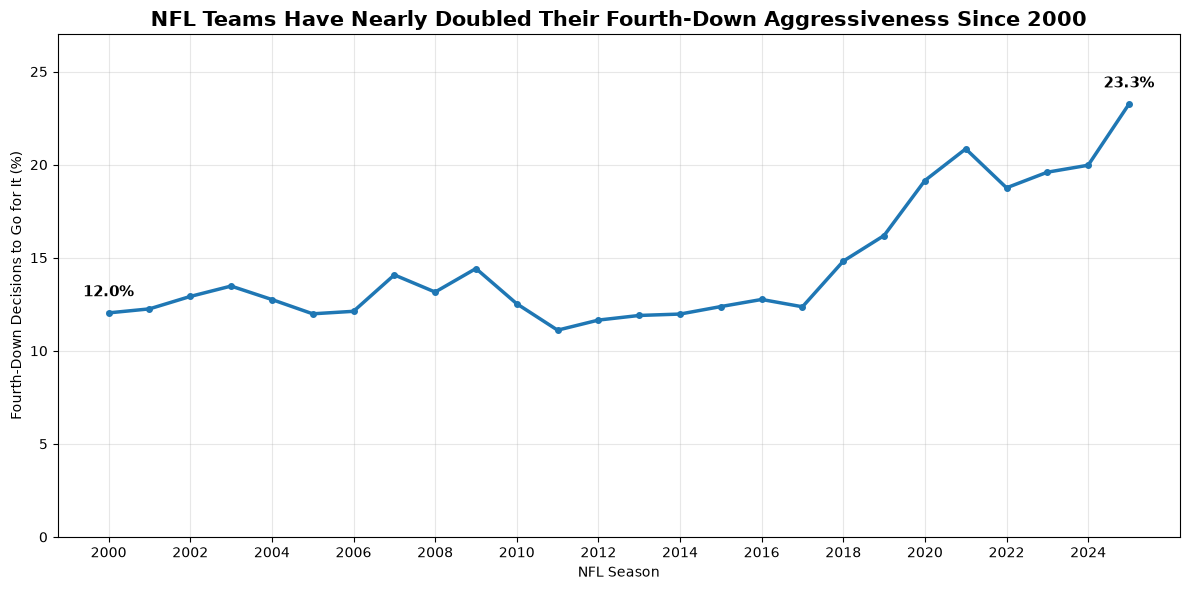

In [10]:
# Convert yearly summary to pandas for plotting
yearly_df = yearly_fourth_down.to_pandas()

# Calculate percentage values
yearly_df["overall_go_pct"] = yearly_df["overall_go_rate"] * 100
yearly_df["conversion_pct"] = yearly_df["conversion_rate"] * 100

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_df["season"],
    yearly_df["overall_go_pct"],
    marker="o",
    markersize=4,
    linewidth=2.5,
    label="Go-for-it rate"
)

# Highlight the beginning and ending values
for year in [2000, 2025]:
    row = yearly_df[yearly_df["season"] == year].iloc[0]

    plt.annotate(
        f'{row["overall_go_pct"]:.1f}%',
        (row["season"], row["overall_go_pct"]),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "NFL Teams Have Nearly Doubled Their Fourth-Down Aggressiveness Since 2000",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("NFL Season")
plt.ylabel("Fourth-Down Decisions to Go for It (%)")

plt.xticks(range(2000, 2026, 2))
plt.grid(alpha=0.3)
plt.ylim(0, 27)

plt.tight_layout()
plt.show()

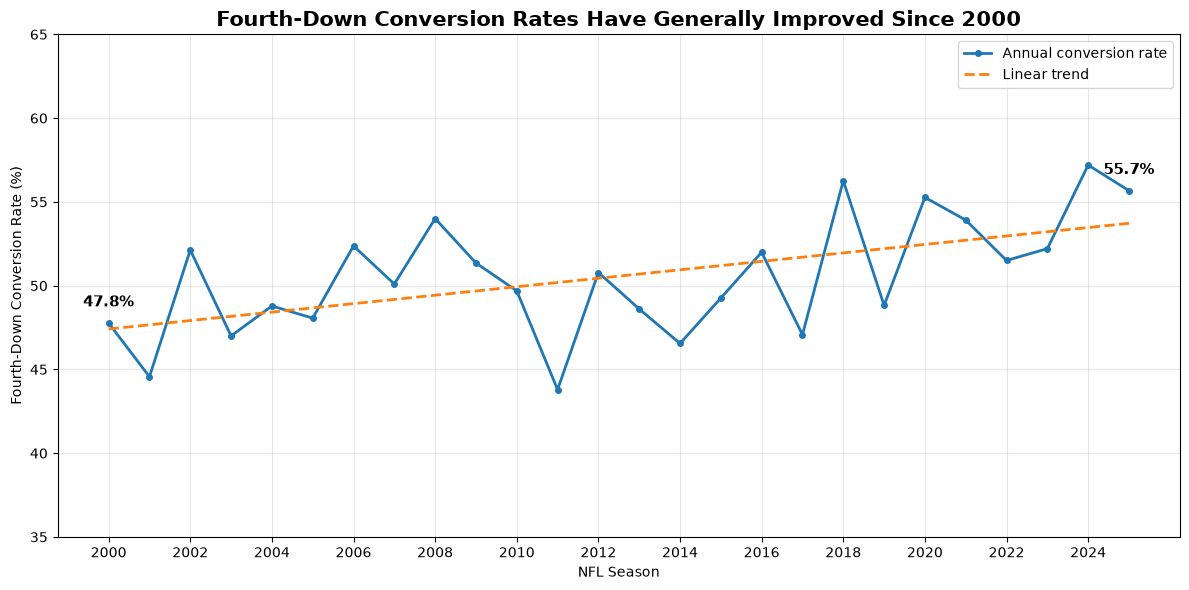

In [11]:
# Fourth-down conversion rate by NFL season (2000–2025)

plt.figure(figsize=(12, 6))

# Annual conversion rates
plt.plot(
    yearly_df["season"],
    yearly_df["conversion_pct"],
    marker="o",
    markersize=4,
    linewidth=2,
    label="Annual conversion rate"
)

# Linear trend line
trend_coefficients = np.polyfit(
    yearly_df["season"],
    yearly_df["conversion_pct"],
    1
)

trend_line = np.poly1d(trend_coefficients)

plt.plot(
    yearly_df["season"],
    trend_line(yearly_df["season"]),
    linestyle="--",
    linewidth=2,
    label="Linear trend"
)

# Label the first and last seasons
for year in [2000, 2025]:
    row = yearly_df[yearly_df["season"] == year].iloc[0]

    plt.annotate(
        f'{row["conversion_pct"]:.1f}%',
        (row["season"], row["conversion_pct"]),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Fourth-Down Conversion Rates Have Generally Improved Since 2000",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("NFL Season")
plt.ylabel("Fourth-Down Conversion Rate (%)")

plt.xticks(range(2000, 2026, 2))
plt.ylim(35, 65)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

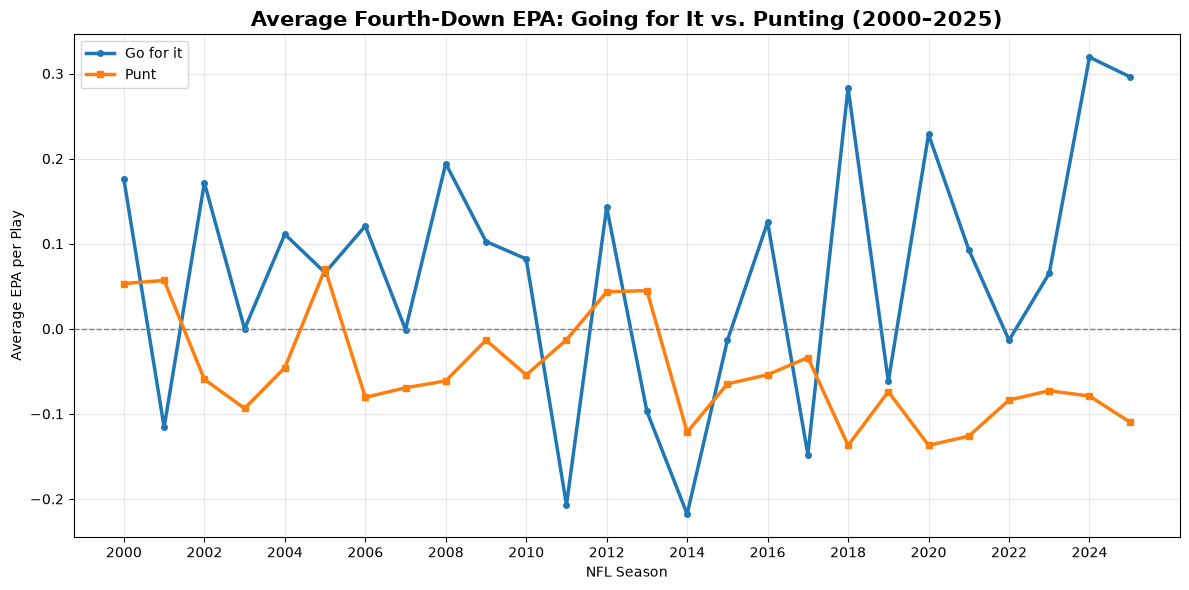

In [12]:
# Average fourth-down EPA by decision (2000–2025)

plt.figure(figsize=(12, 6))

# Average EPA for going for it
plt.plot(
    yearly_df["season"],
    yearly_df["go_avg_epa"],
    marker="o",
    markersize=4,
    linewidth=2.5,
    label="Go for it"
)

# Average EPA for punting
plt.plot(
    yearly_df["season"],
    yearly_df["punt_avg_epa"],
    marker="s",
    markersize=4,
    linewidth=2.5,
    label="Punt"
)

# Reference line at zero EPA
plt.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

plt.title(
    "Average Fourth-Down EPA: Going for It vs. Punting (2000–2025)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("NFL Season")
plt.ylabel("Average EPA per Play")

plt.xticks(range(2000, 2026, 2))
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

## 5. Bears vs. Packers — 2026 Team Comparison

This section compares the Chicago Bears and Green Bay Packers using NFL play-by-play data from the 2026 regular season.

All statistics are calculated using games played on or before November 17, 2026, to prevent information from later games influencing the prediction.

We examine offensive passing and rushing efficiency, defensive performance, and fourth-down decision-making before developing a predictive model.

In [13]:
# Team abbreviations
teams = ["CHI", "GB"]

# Select offensive rushing and passing plays
team_offense_2026 = (
    pbp_2026
    .filter(
        pl.col("posteam").is_in(teams)
        & pl.col("play_type").is_in(["pass", "run"])
        & (pl.col("down") <= 4)
        & pl.col("epa").is_not_null()
        & pl.col("success").is_not_null()
    )
)

# Count offensive plays by team and play type
print(
    team_offense_2026
    .group_by(["posteam", "play_type"])
    .len()
    .sort(["posteam", "play_type"])
)

shape: (4, 3)
┌─────────┬───────────┬─────┐
│ posteam ┆ play_type ┆ len │
│ ---     ┆ ---       ┆ --- │
│ str     ┆ str       ┆ u32 │
╞═════════╪═══════════╪═════╡
│ CHI     ┆ pass      ┆ 331 │
│ CHI     ┆ run       ┆ 293 │
│ GB      ┆ pass      ┆ 395 │
│ GB      ┆ run       ┆ 212 │
└─────────┴───────────┴─────┘


In [14]:
offensive_comparison = (
    team_offense_2026
    .group_by(["posteam", "play_type"])
    .agg(
        pl.len().alias("plays"),

        pl.col("success")
        .mean().alias("success_rate"),

        pl.col("epa")
        .mean().alias("epa_per_play"),

        pl.col("yards_gained")
        .mean().alias("yards_per_play")
    )
    .sort(["posteam", "play_type"])
)

display(
    offensive_comparison
    .to_pandas()
    .round(3)
)

,posteam,play_type,plays,success_rate,epa_per_play,yards_per_play
0,CHI,pass,331,0.492,0.059,6.553
1,CHI,run,293,0.444,0.016,4.403
2,GB,pass,395,0.433,0.119,6.787
3,GB,run,212,0.349,-0.198,3.236


In [15]:
# Select plays where Chicago or Green Bay is on defense

team_defense_2026 = (
    pbp_2026
    .filter(
        pl.col("defteam").is_in(["CHI", "GB"])
        & pl.col("play_type").is_in(["pass", "run"])
        & (pl.col("down") <= 4)
        & pl.col("epa").is_not_null()
        & pl.col("success").is_not_null()
    )
)

# Count defensive plays by team and play type
print(
    team_defense_2026
    .group_by(["defteam", "play_type"])
    .len()
    .sort(["defteam", "play_type"])
)

shape: (4, 3)
┌─────────┬───────────┬─────┐
│ defteam ┆ play_type ┆ len │
│ ---     ┆ ---       ┆ --- │
│ str     ┆ str       ┆ u32 │
╞═════════╪═══════════╪═════╡
│ CHI     ┆ pass      ┆ 285 │
│ CHI     ┆ run       ┆ 183 │
│ GB      ┆ pass      ┆ 383 │
│ GB      ┆ run       ┆ 268 │
└─────────┴───────────┴─────┘


In [16]:
defensive_comparison = (
    team_defense_2026
    .group_by(["defteam", "play_type"])
    .agg(
        pl.len().alias("plays_faced"),

        pl.col("success")
        .mean().alias("opponent_success_rate"),

        pl.col("epa")
        .mean().alias("opponent_epa_per_play"),

        pl.col("yards_gained")
        .mean().alias("opponent_yards_per_play")
    )
    .sort(["defteam", "play_type"])
)

display(
    defensive_comparison
    .to_pandas()
    .round(3)
)

,defteam,play_type,plays_faced,opponent_success_rate,opponent_epa_per_play,opponent_yards_per_play
0,CHI,pass,285,0.400,-0.035,6.940
1,CHI,run,183,0.404,-0.034,4.492
2,GB,pass,383,0.436,-0.036,5.504
3,GB,run,268,0.440,-0.041,4.168


## 6. Predictive Model: Logistic Regression

We develop a logistic regression model to estimate the probability of winning an NFL game.

The model uses historical team performance in passing, rushing, and defense, along with home-field advantage.

To prevent data leakage, all features for a historical game are calculated using only games played before that matchup. Model performance will be evaluated on held-out historical games before predicting the Bears vs. Packers matchup.

In [17]:
# Inspect columns needed to build a game-level prediction dataset

required_columns = [
    "game_id",
    "game_date",
    "season",
    "week",
    "home_team",
    "away_team",
    "home_score",
    "away_score",
    "posteam",
    "defteam",
    "play_type",
    "success",
    "epa"
]

for column in required_columns:
    print(
        f"{column}:",
        "Available" if column in historical_pbp.columns else "Missing"
    )

# Inspect a few unique historical games
historical_games_preview = (
    historical_pbp
    .select([
        "game_id",
        "game_date",
        "season",
        "week",
        "home_team",
        "away_team",
        "home_score",
        "away_score"
    ])
    .unique(subset=["game_id"])
    .sort(["season", "week", "game_id"])
)

display(historical_games_preview.head(10).to_pandas())

game_id: Available
game_date: Available
season: Available
week: Available
home_team: Available
away_team: Available
home_score: Available
away_score: Available
posteam: Available
defteam: Available
play_type: Available
success: Available
epa: Available


,game_id,game_date,season,week,home_team,away_team,home_score,away_score
0,2000_01_ARI_NYG,2000-09-03,2000,1,NYG,ARI,21,16
1,2000_01_BAL_PIT,2000-09-03,2000,1,PIT,BAL,0,16
2,2000_01_CAR_WAS,2000-09-03,2000,1,WAS,CAR,20,17
3,2000_01_CHI_MIN,2000-09-03,2000,1,MIN,CHI,30,27
4,2000_01_DEN_STL,2000-09-04,2000,1,LA,DEN,41,36
5,2000_01_DET_NO,2000-09-03,2000,1,NO,DET,10,14
6,2000_01_IND_KC,2000-09-03,2000,1,KC,IND,14,27
7,2000_01_JAX_CLE,2000-09-03,2000,1,CLE,JAX,7,27
8,2000_01_NYJ_GB,2000-09-03,2000,1,GB,NYJ,16,20
9,2000_01_PHI_DAL,2000-09-03,2000,1,DAL,PHI,14,41


In [18]:
# Create one row per historical NFL game

historical_games = (
    historical_pbp
    .select([
        "game_id",
        "game_date",
        "season",
        "week",
        "home_team",
        "away_team",
        "home_score",
        "away_score"
    ])
    .unique(subset=["game_id"])
    .sort(["season", "week", "game_date", "game_id"])
    .with_columns(
        (pl.col("home_score") - pl.col("away_score"))
        .alias("score_difference")
    )
    .with_columns(
        pl.when(pl.col("score_difference") > 0)
        .then(pl.lit(1))
        .when(pl.col("score_difference") < 0)
        .then(pl.lit(0))
        .otherwise(None)
        .alias("home_win")
    )
)

# Check the number of games and outcomes
print("Total historical games:", historical_games.height)

print(
    historical_games
    .group_by("home_win")
    .len()
    .sort("home_win")
)

# Check for games with missing scores
print(
    "Games with missing scores:",
    historical_games.filter(
        pl.col("home_score").is_null()
        | pl.col("away_score").is_null()
    ).height
)

# Display the first 10 games
display(historical_games.head(10).to_pandas())

Total historical games: 6717
shape: (3, 2)
┌──────────┬──────┐
│ home_win ┆ len  │
│ ---      ┆ ---  │
│ i32      ┆ u32  │
╞══════════╪══════╡
│ null     ┆ 15   │
│ 0        ┆ 2947 │
│ 1        ┆ 3755 │
└──────────┴──────┘
Games with missing scores: 0


,game_id,game_date,season,week,home_team,away_team,home_score,away_score,score_difference,home_win
0,2000_01_ARI_NYG,2000-09-03,2000,1,NYG,ARI,21,16,5,1
1,2000_01_BAL_PIT,2000-09-03,2000,1,PIT,BAL,0,16,-16,0
2,2000_01_CAR_WAS,2000-09-03,2000,1,WAS,CAR,20,17,3,1
3,2000_01_CHI_MIN,2000-09-03,2000,1,MIN,CHI,30,27,3,1
4,2000_01_DET_NO,2000-09-03,2000,1,NO,DET,10,14,-4,0
5,2000_01_IND_KC,2000-09-03,2000,1,KC,IND,14,27,-13,0
6,2000_01_JAX_CLE,2000-09-03,2000,1,CLE,JAX,7,27,-20,0
7,2000_01_NYJ_GB,2000-09-03,2000,1,GB,NYJ,16,20,-4,0
8,2000_01_PHI_DAL,2000-09-03,2000,1,DAL,PHI,14,41,-27,0
9,2000_01_SD_OAK,2000-09-03,2000,1,LV,LAC,9,6,3,1


In [19]:
# Check whether final scores are consistent within each game

score_validation = (
    historical_pbp
    .group_by("game_id")
    .agg(
        pl.col("home_score").n_unique().alias("home_score_values"),
        pl.col("away_score").n_unique().alias("away_score_values")
    )
)

inconsistent_scores = score_validation.filter(
    (pl.col("home_score_values") > 1)
    | (pl.col("away_score_values") > 1)
)

print("Games with inconsistent scores:", inconsistent_scores.height)

display(inconsistent_scores.head(10).to_pandas())

Games with inconsistent scores: 0


,game_id,home_score_values,away_score_values


### 6.1 Historical Team Performance by Game

We first calculate offensive and defensive passing and rushing success rates for each team in each historical game.

These game-level statistics will subsequently be combined using only prior games to construct pregame features for our prediction model.

In [20]:
# Select historical offensive plays with valid success measurements
historical_offensive_plays = (
    historical_pbp
    .filter(
        pl.col("play_type").is_in(["pass", "run"])
        & pl.col("posteam").is_not_null()
        & pl.col("defteam").is_not_null()
        & pl.col("success").is_not_null()
    )
)

# Calculate offensive performance by team and game
game_offense = (
    historical_offensive_plays
    .group_by(["game_id", "posteam"])
    .agg(
        pl.col("success")
        .filter(pl.col("play_type") == "pass")
        .mean()
        .alias("pass_success"),

        pl.col("success")
        .filter(pl.col("play_type") == "run")
        .mean()
        .alias("rush_success"),

        pl.col("play_type")
        .eq("pass")
        .sum()
        .alias("pass_attempts"),

        pl.col("play_type")
        .eq("run")
        .sum()
        .alias("rush_attempts")
    )
    .rename({"posteam": "team"})
)

# Calculate defensive performance by team and game
game_defense = (
    historical_offensive_plays
    .group_by(["game_id", "defteam"])
    .agg(
        pl.col("success")
        .filter(pl.col("play_type") == "pass")
        .mean()
        .alias("pass_success_allowed"),

        pl.col("success")
        .filter(pl.col("play_type") == "run")
        .mean()
        .alias("rush_success_allowed")
    )
    .rename({"defteam": "team"})
)

# Combine offensive and defensive statistics
team_game_stats = (
    game_offense
    .join(
        game_defense,
        on=["game_id", "team"],
        how="inner"
    )
    .join(
        historical_games.select([
            "game_id", "season", "week", "game_date"
        ]),
        on="game_id",
        how="left"
    )
    .sort(["team", "season", "week", "game_date"])
)

print("Total team-game records:", team_game_stats.height)

display(team_game_stats.head(10).to_pandas().round(3))

Total team-game records: 13434


,game_id,team,pass_success,rush_success,pass_attempts,rush_attempts,pass_success_allowed,rush_success_allowed,season,week,game_date
0,2000_01_ARI_NYG,ARI,0.412,0.250,51,20,0.458,0.415,2000,1,2000-09-03
1,2000_02_DAL_ARI,ARI,0.615,0.424,26,33,0.429,0.524,2000,2,2000-09-10
2,2000_04_GB_ARI,ARI,0.395,0.231,43,13,0.515,0.389,2000,4,2000-09-24
3,2000_05_ARI_SF,ARI,0.488,0.348,41,23,0.471,0.419,2000,5,2000-10-01
4,2000_06_CLE_ARI,ARI,0.290,0.406,31,32,0.348,0.367,2000,6,2000-10-08
5,2000_07_PHI_ARI,ARI,0.357,0.500,28,14,0.514,0.553,2000,7,2000-10-15
6,2000_08_ARI_DAL,ARI,0.375,0.417,32,24,0.562,0.590,2000,8,2000-10-22
7,2000_09_NO_ARI,ARI,0.420,0.538,50,26,0.429,0.429,2000,9,2000-10-29
8,2000_10_WAS_ARI,ARI,0.550,0.208,20,24,0.436,0.486,2000,10,2000-11-05
9,2000_11_ARI_MIN,ARI,0.433,0.389,30,18,0.629,0.312,2000,11,2000-11-12


### 6.2 Pregame Team Performance

To prevent data leakage, we calculate each team's season-to-date offensive and defensive success rates using only games played before the game being predicted.

We use cumulative averages shifted by one game, ensuring that the current game's performance is excluded from its prediction features.

For this initial model, games without prior-season performance data are excluded from training.

In [22]:
# Sort games chronologically within each team and season
team_game_stats = team_game_stats.sort(
    ["team", "season", "week", "game_date", "game_id"]
)

# Calculate pregame averages using previous games only
pregame_team_stats = (
    team_game_stats
    .with_columns(
        pl.col("game_id")
        .cum_count()
        .over(["team", "season"])
        .alias("games_played_including_current")
    )
    .with_columns(
        (
            pl.col("games_played_including_current") - 1
        ).alias("prior_games")
    )
    .with_columns(
        pl.col("pass_success")
        .shift(1)
        .rolling_mean(window_size=100, min_samples=1)
        .over(["team", "season"])
        .alias("pregame_pass_success"),

        pl.col("rush_success")
        .shift(1)
        .rolling_mean(window_size=100, min_samples=1)
        .over(["team", "season"])
        .alias("pregame_rush_success"),

        pl.col("pass_success_allowed")
        .shift(1)
        .rolling_mean(window_size=100, min_samples=1)
        .over(["team", "season"])
        .alias("pregame_pass_success_allowed"),

        pl.col("rush_success_allowed")
        .shift(1)
        .rolling_mean(window_size=100, min_samples=1)
        .over(["team", "season"])
        .alias("pregame_rush_success_allowed")
    )
)

# Inspect Arizona's first several games in 2000
display(
    pregame_team_stats
    .filter(
        (pl.col("team") == "ARI")
        & (pl.col("season") == 2000)
    )
    .select([
        "week",
        "pass_success",
        "pregame_pass_success",
        "rush_success",
        "pregame_rush_success",
        "prior_games"
    ])
    .head(8)
    .to_pandas()
    .round(3)
)

,week,pass_success,pregame_pass_success,rush_success,pregame_rush_success,prior_games
0,1,0.412,NaN,0.250,NaN,0
1,2,0.615,0.412,0.424,0.250,1
2,4,0.395,0.514,0.231,0.337,2
3,5,0.488,0.474,0.348,0.302,3
4,6,0.290,0.478,0.406,0.313,4
5,7,0.357,0.440,0.500,0.332,5
6,8,0.375,0.426,0.417,0.360,6
7,9,0.420,0.419,0.538,0.368,7


### 6.3 Constructing Game-Level Prediction Features

We combine each game's home and away team statistics into a single observation.

The predictive features represent differences in pregame offensive and defensive performance between the two teams.

For offensive success rates, positive differences favor the home team. For defensive success rates allowed, positive differences indicate that the home team allows fewer successful plays.

Games where either team has no previous games in the season are excluded from the initial training dataset.

In [23]:
# Select pregame statistics needed for the prediction model
feature_columns = [
    "pregame_pass_success",
    "pregame_rush_success",
    "pregame_pass_success_allowed",
    "pregame_rush_success_allowed"
]

# Prepare home team statistics
home_features = (
    pregame_team_stats
    .select(["game_id", "team", "prior_games"] + feature_columns)
    .rename({
        "team": "home_team",
        "prior_games": "home_prior_games",
        **{col: f"home_{col}" for col in feature_columns}
    })
)

# Prepare away team statistics
away_features = (
    pregame_team_stats
    .select(["game_id", "team", "prior_games"] + feature_columns)
    .rename({
        "team": "away_team",
        "prior_games": "away_prior_games",
        **{col: f"away_{col}" for col in feature_columns}
    })
)

# Combine home and away team statistics
model_games = (
    historical_games
    .join(
        home_features,
        on=["game_id", "home_team"],
        how="inner"
    )
    .join(
        away_features,
        on=["game_id", "away_team"],
        how="inner"
    )
    .filter(
        (pl.col("home_prior_games") > 0)
        & (pl.col("away_prior_games") > 0)
        & pl.col("home_win").is_not_null()
    )
    .with_columns(
        (
            pl.col("home_pregame_pass_success")
            - pl.col("away_pregame_pass_success")
        ).alias("pass_success_diff"),

        (
            pl.col("home_pregame_rush_success")
            - pl.col("away_pregame_rush_success")
        ).alias("rush_success_diff"),

        (
            pl.col("away_pregame_pass_success_allowed")
            - pl.col("home_pregame_pass_success_allowed")
        ).alias("pass_defense_diff"),

        (
            pl.col("away_pregame_rush_success_allowed")
            - pl.col("home_pregame_rush_success_allowed")
        ).alias("rush_defense_diff")
    )
    .drop_nulls([
        "pass_success_diff",
        "rush_success_diff",
        "pass_defense_diff",
        "rush_defense_diff"
    ])
    .sort(["season", "week", "game_date", "game_id"])
)

print("Games available for modeling:", model_games.height)

display(
    model_games.select([
        "season",
        "week",
        "home_team",
        "away_team",
        "pass_success_diff",
        "rush_success_diff",
        "pass_defense_diff",
        "rush_defense_diff",
        "home_win"
    ])
    .head(10)
    .to_pandas()
    .round(3)
)

Games available for modeling: 6288


,season,week,home_team,away_team,pass_success_diff,rush_success_diff,pass_defense_diff,rush_defense_diff,home_win
0,2000,2,DEN,ATL,0.080,0.080,-0.038,0.042,1
1,2000,2,SF,CAR,0.213,-0.025,0.120,0.075,0
2,2000,2,TB,CHI,-0.117,-0.193,-0.008,0.173,1
3,2000,2,ARI,DAL,0.217,-0.135,-0.025,0.172,1
4,2000,2,BUF,GB,-0.010,-0.027,0.190,0.206,1
5,2000,2,BAL,JAX,-0.181,0.094,-0.054,0.153,1
6,2000,2,TEN,KC,-0.056,0.033,0.151,0.058,1
7,2000,2,MIN,MIA,0.098,0.034,-0.215,-0.535,1
8,2000,2,LAC,NO,0.062,0.030,-0.114,0.146,0
9,2000,2,PHI,NYG,-0.025,0.172,0.217,-0.135,0


### 6.4 Training and Testing Split

We use a chronological train-test split to evaluate the logistic regression model.

- Training data: 2000–2024 NFL regular seasons
- Testing data: 2025 NFL regular season

The model is trained only on earlier seasons and evaluated on a later, unseen season.

This approach better reflects the real-world prediction task than randomly dividing games into training and testing sets.

In [24]:
# Features used by the logistic regression model
model_features = [
    "pass_success_diff",
    "rush_success_diff",
    "pass_defense_diff",
    "rush_defense_diff"
]

# Chronological train-test split
train_games = model_games.filter(
    pl.col("season") <= 2024
)

test_games = model_games.filter(
    pl.col("season") == 2025
)

# Convert features and targets to NumPy arrays
X_train = train_games.select(model_features).to_numpy()
y_train = train_games["home_win"].to_numpy()

X_test = test_games.select(model_features).to_numpy()
y_test = test_games["home_win"].to_numpy()

# Verify the split
print("Training games:", len(X_train))
print("Testing games:", len(X_test))

print("\nTraining seasons:")
print(train_games["season"].min(), "-", train_games["season"].max())

print("\nTesting season:")
print(test_games["season"].unique().to_list())

print("\nTraining home-win rate:", round(y_train.mean(), 3))
print("Testing home-win rate:", round(y_test.mean(), 3))

Training games: 6033
Testing games: 255

Training seasons:
2000 - 2024

Testing season:
[2025]

Training home-win rate: 0.562
Testing home-win rate: 0.537


### 6.5 Logistic Regression Model Training and Evaluation

We train a logistic regression classifier using historical NFL games from 2000–2024 and evaluate its performance on the 2025 season.

The model predicts the probability that the home team wins based on differences in pregame offensive and defensive success rates.

We evaluate the model using accuracy, ROC AUC, Brier score, and log loss. We also compare its accuracy against a baseline that always predicts the home team.

# Train the logistic regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train, y_train)

# Generate predictions for the 2025 test season
y_pred = logistic_model.predict(X_test)

# Predicted probability that the home team wins
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate predictive performance
accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
brier = brier_score_loss(y_test, y_prob)
logloss = log_loss(y_test, y_prob)

# Baseline: always predict the home team wins
baseline_pred = np.ones_like(y_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print(f"Accuracy:          {accuracy:.3f}")
print(f"ROC AUC:           {auc:.3f}")
print(f"Brier Score:       {brier:.3f}")
print(f"Log Loss:          {logloss:.3f}")

print("\nBASELINE COMPARISON")
print("---------------------------")
print(f"Always Home Accuracy: {baseline_accuracy:.3f}")
print(f"Model Accuracy:       {accuracy:.3f}")
print(f"Improvement:          {accuracy - baseline_accuracy:+.3f}")

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))

## 7. Bears vs. Packers — Christmas Day 2026 Prediction

We use our trained logistic regression model to estimate the probability of winning the Christmas Day matchup between the Chicago Bears and Green Bay Packers.

The prediction uses 2026 regular-season performance data available through November 17, 2026.

Our model considers differences in offensive passing and rushing success rates, as well as defensive passing and rushing success rates allowed.

In [27]:
# Extract 2026 offensive success rates
offense_2026 = (
    offensive_comparison
    .select(["posteam", "play_type", "success_rate"])
    .to_pandas()
    .set_index(["posteam", "play_type"])["success_rate"]
)

# Extract 2026 defensive success rates allowed
defense_2026 = (
    defensive_comparison
    .select(["defteam", "play_type", "opponent_success_rate"])
    .to_pandas()
    .set_index(["defteam", "play_type"])["opponent_success_rate"]
)

# Calculate differences from Chicago's perspective
matchup_features = {
    "pass_success_diff":
        offense_2026["CHI", "pass"] - offense_2026["GB", "pass"],

    "rush_success_diff":
        offense_2026["CHI", "run"] - offense_2026["GB", "run"],

    "pass_defense_diff":
        defense_2026["GB", "pass"] - defense_2026["CHI", "pass"],

    "rush_defense_diff":
        defense_2026["GB", "run"] - defense_2026["CHI", "run"]
}

matchup_df = pd.DataFrame(
    [matchup_features],
    index=["CHI minus GB"]
)

display(matchup_df.round(3))

,pass_success_diff,rush_success_diff,pass_defense_diff,rush_defense_diff
CHI minus GB,0.06,0.095,0.036,0.036


In [29]:
# Chicago is the home team for the Christmas Day game

prediction_input = matchup_df[model_features]

# Predict home-team (Chicago) win probability
bears_win_prob = logistic_model.predict_proba(
    prediction_input.to_numpy()
)[0, 1]

packers_win_prob = 1 - bears_win_prob

predicted_winner = (
    "Chicago Bears"
    if bears_win_prob >= 0.5
    else "Green Bay Packers"
)

print("CHRISTMAS DAY 2026 PREDICTION")
print("-----------------------------")
print(f"Chicago Bears:    {bears_win_prob:.1%}")
print(f"Green Bay Packers: {packers_win_prob:.1%}")
print(f"Predicted winner: {predicted_winner}")

CHRISTMAS DAY 2026 PREDICTION
-----------------------------
Chicago Bears:    71.9%
Green Bay Packers: 28.1%
Predicted winner: Chicago Bears


### 7.1 Predicted Win Probabilities

Our logistic regression model predicts a Chicago Bears victory over the Green Bay Packers on December 25, 2026.

The model estimates win probabilities using passing and rushing success rates, defensive performance, and home-field advantage, based on data available through November 17, 2026.

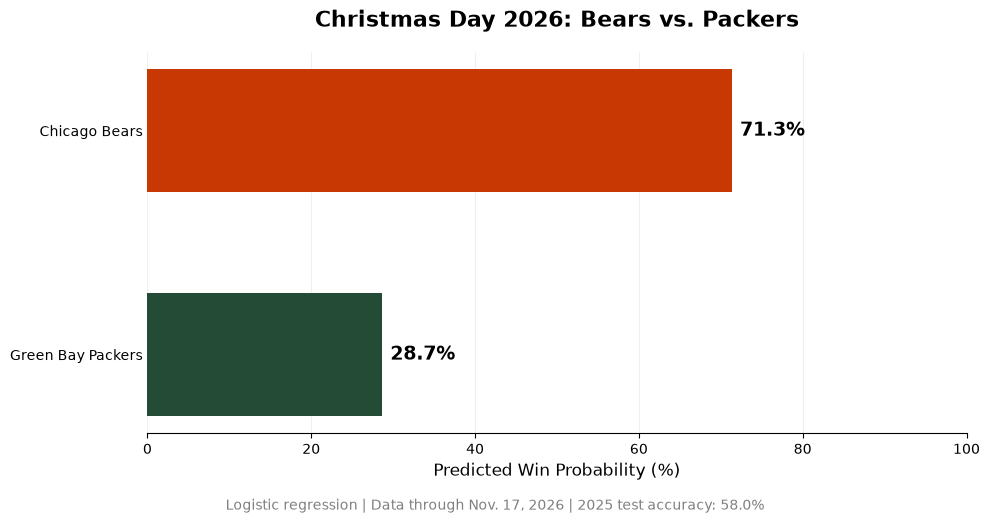

In [34]:
# Create a presentation-ready win probability chart

teams = ["Chicago Bears", "Green Bay Packers"]
probabilities = [bears_win_prob * 100, packers_win_prob * 100]
colors = ["#C83803", "#244B35"]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    teams,
    probabilities,
    color=colors,
    height=0.55
)

ax.invert_yaxis()

for bar, probability in zip(bars, probabilities):
    ax.text(
        probability + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{probability:.1f}%",
        va="center",
        fontsize=14,
        fontweight="bold"
    )

ax.set_xlim(0, 100)
ax.set_xlabel("Predicted Win Probability (%)", fontsize=12)
ax.set_title(
    "Christmas Day 2026: Bears vs. Packers",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.figtext(
    0.5, -0.03,
    "Logistic regression | Data through Nov. 17, 2026 | "
    "2025 test accuracy: 58.0%",
    ha="center",
    fontsize=10,
    color="gray"
)

plt.tight_layout()

# Save for presentation
plt.savefig(
    "figures/bears_packers_prediction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
# Calculate 2026 game-level success rates
team_game_2026 = (
    pbp_2026
    .filter(
        pl.col("play_type").is_in(["pass", "run"])
        & pl.col("posteam").is_not_null()
        & pl.col("defteam").is_not_null()
        & pl.col("success").is_not_null()
    )
    .group_by(["game_id", "posteam", "defteam", "play_type"])
    .agg(
        pl.col("success").mean().alias("success_rate")
    )
)

# Offensive averages across games
offense_game_avg = (
    team_game_2026
    .group_by(["posteam", "play_type"])
    .agg(
        pl.col("success_rate").mean().alias("avg_success")
    )
    .filter(pl.col("posteam").is_in(["CHI", "GB"]))
)

# Defensive averages across games
defense_game_avg = (
    team_game_2026
    .group_by(["defteam", "play_type"])
    .agg(
        pl.col("success_rate").mean().alias("avg_success_allowed")
    )
    .filter(pl.col("defteam").is_in(["CHI", "GB"]))
)

print("OFFENSIVE GAME-AVERAGED SUCCESS RATES")
display(offense_game_avg.to_pandas().round(3))

print("DEFENSIVE GAME-AVERAGED SUCCESS RATES")
display(defense_game_avg.to_pandas().round(3))

OFFENSIVE GAME-AVERAGED SUCCESS RATES


,posteam,play_type,avg_success
0,GB,run,0.350
1,GB,pass,0.439
2,CHI,run,0.439
3,CHI,pass,0.498


DEFENSIVE GAME-AVERAGED SUCCESS RATES


,defteam,play_type,avg_success_allowed
0,CHI,pass,0.404
1,GB,pass,0.448
2,GB,run,0.435
3,CHI,run,0.409


In [33]:
# Convert game-averaged offensive rates into a lookup
offense_avg = (
    offense_game_avg
    .to_pandas()
    .set_index(["posteam", "play_type"])["avg_success"]
)

# Convert game-averaged defensive rates into a lookup
defense_avg = (
    defense_game_avg
    .to_pandas()
    .set_index(["defteam", "play_type"])["avg_success_allowed"]
)

# Build features from Chicago's perspective (home team)
updated_matchup_features = {
    "pass_success_diff":
        offense_avg["CHI", "pass"] - offense_avg["GB", "pass"],

    "rush_success_diff":
        offense_avg["CHI", "run"] - offense_avg["GB", "run"],

    "pass_defense_diff":
        defense_avg["GB", "pass"] - defense_avg["CHI", "pass"],

    "rush_defense_diff":
        defense_avg["GB", "run"] - defense_avg["CHI", "run"]
}

# Create prediction input with the same feature order as training
updated_matchup_df = pd.DataFrame(
    [updated_matchup_features]
)[model_features]

# Predict using the existing logistic regression model
bears_win_prob = logistic_model.predict_proba(
    updated_matchup_df.to_numpy()
)[0, 1]

packers_win_prob = 1 - bears_win_prob

predicted_winner = (
    "Chicago Bears"
    if bears_win_prob >= 0.5
    else "Green Bay Packers"
)

print("UPDATED CHRISTMAS DAY 2026 PREDICTION")
print("------------------------------------")
print(f"Chicago Bears:     {bears_win_prob:.1%}")
print(f"Green Bay Packers: {packers_win_prob:.1%}")
print(f"Predicted winner:  {predicted_winner}")

display(updated_matchup_df.round(3))

UPDATED CHRISTMAS DAY 2026 PREDICTION
------------------------------------
Chicago Bears:     71.3%
Green Bay Packers: 28.7%
Predicted winner:  Chicago Bears


,pass_success_diff,rush_success_diff,pass_defense_diff,rush_defense_diff
0,0.058,0.088,0.044,0.027


Our model favors Chicago for several reasons:
- Chicago has a 5.8-percentage-point advantage in passing success rate.
- Chicago has an 8.8-percentage-point advantage in rushing success rate.
- Chicago's defense allows fewer successful passing and rushing plays.
- Chicago also benefits from playing at home.
  
The model was evaluated on 255 games from the 2025 NFL season, achieving 58.0% accuracy, compared with 53.7% for an always-predict-home baseline.